## 1. LOADING DATASET AND UNDERSTANDING

In [1]:
import numpy as np
import pandas as pd

In [2]:
data = pd.read_csv('/Users/priyap/Documents/Project_2/loans_granting_model_dataset.csv')

/var/folders/r0/tjp2c5m91yx7lrfby4dh8hd40000gn/T/ipykernel_1437/1052831067.py:1: DtypeWarning: Columns (0: desc) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv('/Users/priyap/Documents/Project_2/loans_granting_model_dataset.csv')


In [3]:
data.shape

(1347681, 15)

In [4]:
data.head()

,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN


In [5]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 1347681 entries, 0 to 1347680
Data columns (total 15 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   id                1347681 non-null  int64  
 1   issue_d           1347681 non-null  str    
 2   revenue           1347681 non-null  float64
 3   dti_n             1347681 non-null  float64
 4   loan_amnt         1347681 non-null  int64  
 5   fico_n            1347681 non-null  float64
 6   experience_c      1347681 non-null  int64  
 7   emp_length        1347681 non-null  str    
 8   purpose           1347681 non-null  str    
 9   home_ownership_n  1347681 non-null  str    
 10  addr_state        1347681 non-null  str    
 11  zip_code          1347680 non-null  str    
 12  Default           1347681 non-null  int64  
 13  title             1331024 non-null  str    
 14  desc              119099 non-null   str    
dtypes: float64(3), int64(4), str(8)
memory usage: 254.5 MB
None


In [6]:
for col in data.columns:
    print(col)

id
issue_d
revenue
dti_n
loan_amnt
fico_n
experience_c
emp_length
purpose
home_ownership_n
addr_state
zip_code
Default
title
desc


In [7]:
data.describe(include='all')

,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
count,1.347681e+06,1347681,1.347681e+06,1.347681e+06,1.347681e+06,1.347681e+06,1.347681e+06,1347681,1347681,1347681,1347681,1347680,1.347681e+06,1331024,119099
unique,NaN,139,NaN,NaN,NaN,NaN,NaN,12,14,4,51,945,NaN,61451,109539
top,NaN,Mar-2016,NaN,NaN,NaN,NaN,NaN,10+ years,debt_consolidation,MORTGAGE,CA,945xx,NaN,Debt consolidation,Debt consolidation.
freq,NaN,48927,NaN,NaN,NaN,NaN,NaN,442667,781206,666594,196805,15013,NaN,661113,1170
mean,5.621359e+07,NaN,7.736968e+04,1.829909e+01,1.440823e+04,6.981589e+02,9.999814e-01,NaN,NaN,NaN,NaN,NaN,1.997869e-01,NaN,NaN
std,3.839501e+07,NaN,7.036299e+04,1.115214e+01,8.715347e+03,3.184872e+01,4.306977e-03,NaN,NaN,NaN,NaN,NaN,3.998402e-01,NaN,NaN
min,5.473400e+04,NaN,1.896000e+03,0.000000e+00,5.000000e+02,6.120000e+02,0.000000e+00,NaN,NaN,NaN,NaN,NaN,0.000000e+00,NaN,NaN
25%,1.970651e+07,NaN,4.660000e+04,1.182000e+01,7.975000e+03,6.720000e+02,1.000000e+00,NaN,NaN,NaN,NaN,NaN,0.000000e+00,NaN,NaN
50%,5.766422e+07,NaN,6.500000e+04,1.763000e+01,1.200000e+04,6.920000e+02,1.000000e+00,NaN,NaN,NaN,NaN,NaN,0.000000e+00,NaN,NaN
75%,8.449505e+07,NaN,9.200000e+04,2.407000e+01,2.000000e+04,7.120000e+02,1.000000e+00,NaN,NaN,NaN,NaN,NaN,0.000000e+00,NaN,NaN


## 2. DATA PREPROCESSING

In [8]:
print("Duplicate Rows:", data.duplicated().sum())

print("Duplicate IDs:", data['id'].duplicated().sum())

Duplicate Rows: 0
Duplicate IDs: 0


In [9]:
categorical_columns = [
    'emp_length',
    'purpose',
    'home_ownership_n',
    'addr_state',
    'zip_code',
    'title'
]

for col in categorical_columns:
    print(f"\nColumn: {col}")
    print("Unique values:", data[col].nunique())
    print(data[col].value_counts(dropna=False).head(20))


Column: emp_length
Unique values: 12
emp_length
10+ years    442667
2 years      122091
< 1 year     108517
3 years      107862
1 year        88841
5 years       84326
4 years       80761
NI            78188
6 years       62877
8 years       60808
7 years       59724
9 years       51019
Name: count, dtype: int64

Column: purpose
Unique values: 14
purpose
debt_consolidation    781206
credit_card           295551
home_improvement       87684
other                  78263
major_purchase         29543
medical                15606
small_business         15575
car                    14647
moving                  9520
vacation                9083
house                   7294
wedding                 2350
renewable_energy         936
educational              423
Name: count, dtype: int64

Column: home_ownership_n
Unique values: 4
home_ownership_n
MORTGAGE    666594
RENT        535585
OWN         144985
OTHER          517
Name: count, dtype: int64

Column: addr_state
Unique values: 51
addr_state

In [10]:
#Missing Value Identification:
print("Missing Count: ", data.isna().sum())

Missing Count:  id                        0
issue_d                   0
revenue                   0
dti_n                     0
loan_amnt                 0
fico_n                    0
experience_c              0
emp_length                0
purpose                   0
home_ownership_n          0
addr_state                0
zip_code                  1
Default                   0
title                 16657
desc                1228582
dtype: int64


In [11]:
print("Missing Percentage: ", data.isna().mean().mul(100))

Missing Percentage:  id                   0.000000
issue_d              0.000000
revenue              0.000000
dti_n                0.000000
loan_amnt            0.000000
fico_n               0.000000
experience_c         0.000000
emp_length           0.000000
purpose              0.000000
home_ownership_n     0.000000
addr_state           0.000000
zip_code             0.000074
Default              0.000000
title                1.235975
desc                91.162671
dtype: float64


In [12]:
# Categorical and their frequencies.
categorical_review_cols = [
    c for c in ["emp_length", "purpose", "home_ownership_n", "addr_state", "zip_code"]
]

for col in categorical_review_cols:
    print(f"\\n{col}: {data[col].nunique(dropna=True)} unique values")

\nemp_length: 12 unique values
\npurpose: 14 unique values
\nhome_ownership_n: 4 unique values
\naddr_state: 51 unique values
\nzip_code: 945 unique values


In [13]:
for col in categorical_review_cols:
    print(data[col].value_counts(dropna=False).head(25))

emp_length
10+ years    442667
2 years      122091
< 1 year     108517
3 years      107862
1 year        88841
5 years       84326
4 years       80761
NI            78188
6 years       62877
8 years       60808
7 years       59724
9 years       51019
Name: count, dtype: int64
purpose
debt_consolidation    781206
credit_card           295551
home_improvement       87684
other                  78263
major_purchase         29543
medical                15606
small_business         15575
car                    14647
moving                  9520
vacation                9083
house                   7294
wedding                 2350
renewable_energy         936
educational              423
Name: count, dtype: int64
home_ownership_n
MORTGAGE    666594
RENT        535585
OWN         144985
OTHER          517
Name: count, dtype: int64
addr_state
CA    196805
TX    110307
NY    110075
FL     95815
IL     51858
NJ     48576
PA     45640
OH     43935
GA     43470
VA     38107
NC     37812
MI     353

In [14]:
if "Default" in data.columns:
    print("Default values:")
    display(data["Default"].value_counts(dropna=False))
    print("Default proportions (%):")
    display(data["Default"].value_counts(normalize=True, dropna=False).mul(100))

Default values:


Default
0    1078432
1     269249
Name: count, dtype: int64

Default proportions (%):


Default
0    80.021311
1    19.978689
Name: proportion, dtype: float64

## 3. DATA CLEANING AND FEATURE PREPARATION

In [15]:
#Creating a copy so that we keep that original data.
df = data.copy()

In [16]:
if "issue_d" in df.columns:
    df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y", errors="coerce")
    df["issue_year"] = df["issue_d"].dt.year
    df["issue_month"] = df["issue_d"].dt.month

for c in df['issue_d'].unique():
    print(c)

2015-12-01 00:00:00
2015-11-01 00:00:00
2015-10-01 00:00:00
2015-09-01 00:00:00
2015-08-01 00:00:00
2015-07-01 00:00:00
2015-06-01 00:00:00
2015-05-01 00:00:00
2015-04-01 00:00:00
2015-03-01 00:00:00
2015-02-01 00:00:00
2015-01-01 00:00:00
2018-03-01 00:00:00
2018-02-01 00:00:00
2018-01-01 00:00:00
2017-09-01 00:00:00
2017-08-01 00:00:00
2017-07-01 00:00:00
2016-06-01 00:00:00
2016-05-01 00:00:00
2016-04-01 00:00:00
2018-09-01 00:00:00
2018-08-01 00:00:00
2018-07-01 00:00:00
2017-06-01 00:00:00
2017-05-01 00:00:00
2017-04-01 00:00:00
2016-03-01 00:00:00
2016-02-01 00:00:00
2016-01-01 00:00:00
2014-12-01 00:00:00
2014-11-01 00:00:00
2014-10-01 00:00:00
2014-09-01 00:00:00
2014-08-01 00:00:00
2014-07-01 00:00:00
2014-06-01 00:00:00
2014-05-01 00:00:00
2014-04-01 00:00:00
2014-03-01 00:00:00
2014-02-01 00:00:00
2014-01-01 00:00:00
2018-12-01 00:00:00
2018-11-01 00:00:00
2018-10-01 00:00:00
2018-06-01 00:00:00
2018-05-01 00:00:00
2018-04-01 00:00:00
2011-12-01 00:00:00
2011-11-01 00:00:00


In [17]:
default_values = set(pd.Series(df["Default"].dropna().unique()).tolist())
print("Observed Default values:", default_values)

Observed Default values: {0, 1}


In [18]:

# Checking whether the numeric feature is constant or not constant.

numeric_candidates = [
    c for c in ["revenue", "dti_n", "loan_amnt", "fico_n", "experience_c",
                "issue_year", "issue_month"]
    if c in df.columns
]
constant_cols = [c for c in numeric_candidates if df[c].nunique(dropna=True) <= 1]
print("Constant numerical columns (excluded):", constant_cols)

Constant numerical columns (excluded): []


In [19]:
NumData_for_eda = [
    c for c in ["revenue", "dti_n", "loan_amnt", "fico_n", "experience_c"]
    if c in df.columns and c not in constant_cols
]

display(df[NumData_for_eda].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
revenue,1347681.0,77369.683174,70362.989597,1896.0,19000.0,28329.0,46600.00,65000.00,92000.00,160000.00,260000.00,10999200.0
dti_n,1347681.0,18.299091,11.152139,0.0,1.8,5.0,11.82,17.63,24.07,32.99,38.48,999.0
loan_amnt,1347681.0,14408.230490,8715.347372,500.0,1500.0,3200.0,7975.00,12000.00,20000.00,32800.00,35000.00,40000.0
fico_n,1347681.0,698.158922,31.848725,612.0,662.0,662.0,672.00,692.00,712.00,762.00,802.00,847.5
experience_c,1347681.0,0.999981,0.004307,0.0,1.0,1.0,1.00,1.00,1.00,1.00,1.00,1.0


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
RANDOM_STATE = 42

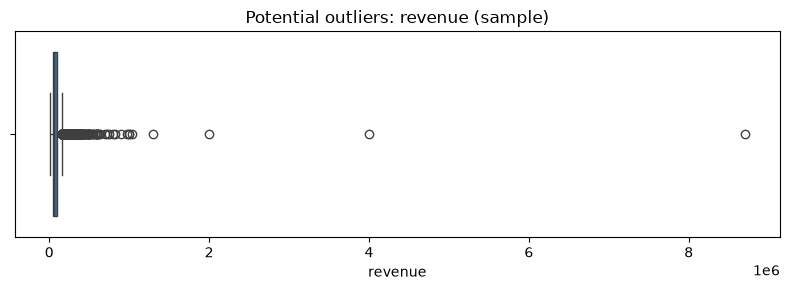

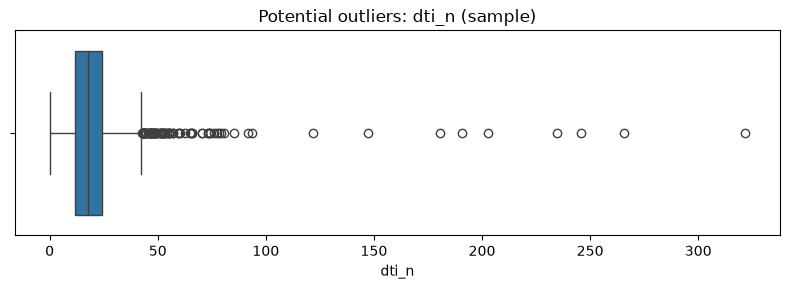

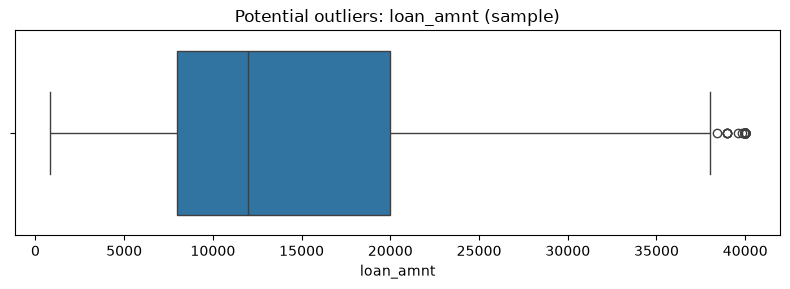

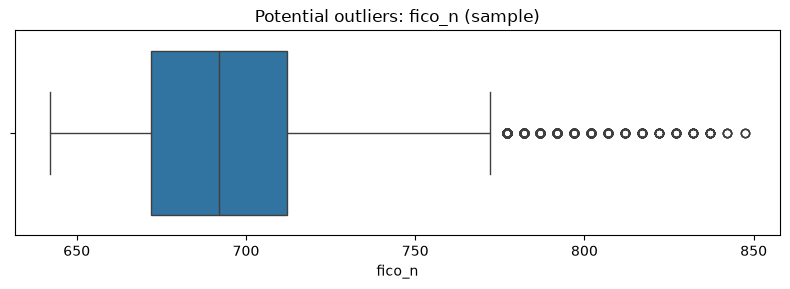

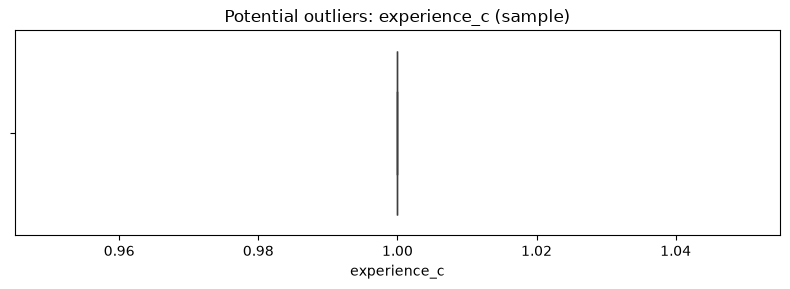

In [21]:
# Boxplots use a random sample to keep plotting responsive.
eda_sample = df.sample(n=min(20000, len(df)), random_state=RANDOM_STATE)
for col in NumData_for_eda:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=eda_sample[col])
    plt.title(f"Potential outliers: {col} (sample)")
    plt.tight_layout()
    plt.show()

In [22]:
#Outlier Detection using IQR method

iqr_rows = []
for col in NumData_for_eda:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    iqr_rows.append([col, lower, upper, int(count), count / len(df) * 100])

iqr_summary = pd.DataFrame(
    iqr_rows,
    columns=["feature", "iqr_lower_bound", "iqr_upper_bound", "outlier_count", "outlier_percentage"]
)

display(iqr_summary)
#iqr_summary.to_csv(os.path.join(OUTPUT_DIR, "iqr_outlier_summary.csv"), index=False)

,feature,iqr_lower_bound,iqr_upper_bound,outlier_count,outlier_percentage
0,revenue,-21500.000,160100.000,62998,4.674548
1,dti_n,-6.555,42.445,5506,0.408554
2,loan_amnt,-10062.500,38037.500,7131,0.529131
3,fico_n,612.000,772.000,46490,3.449629
4,experience_c,1.000,1.000,25,0.001855


## 4. EXPLORTORY DATA ANALYSIS

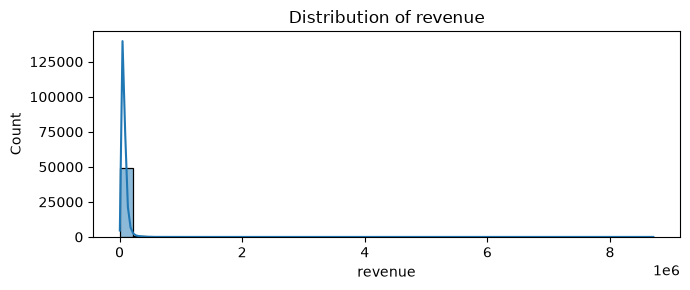

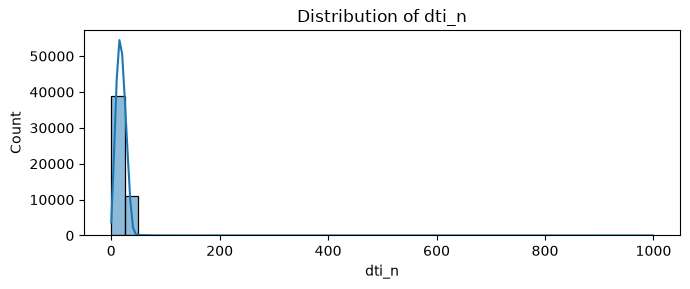

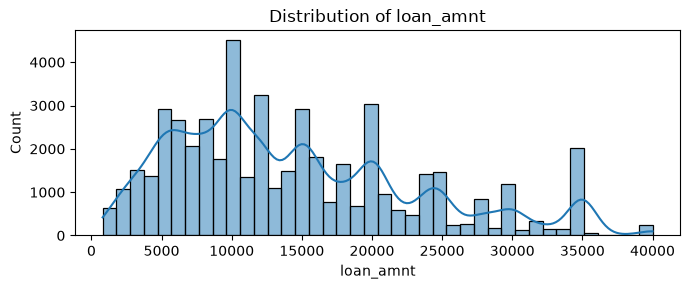

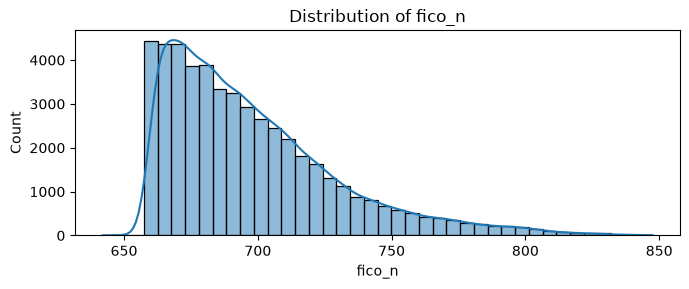

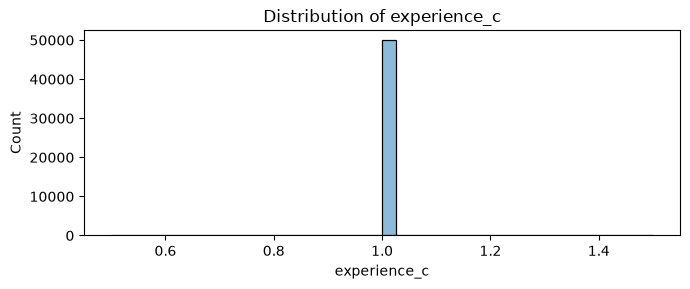

In [23]:
# Univariate distributions
for col in NumData_for_eda:
    plt.figure(figsize=(7, 3))
    sns.histplot(df[col].dropna().sample(
        n=min(50000, df[col].notna().sum()), random_state=RANDOM_STATE
    ), bins=40, kde=True)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

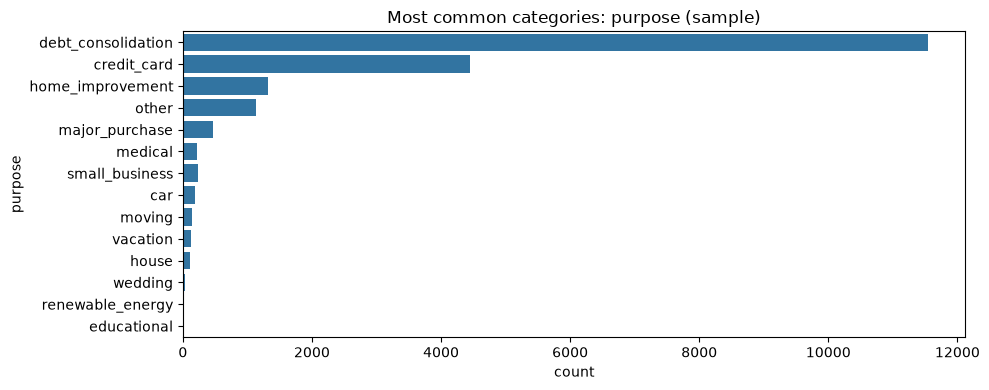

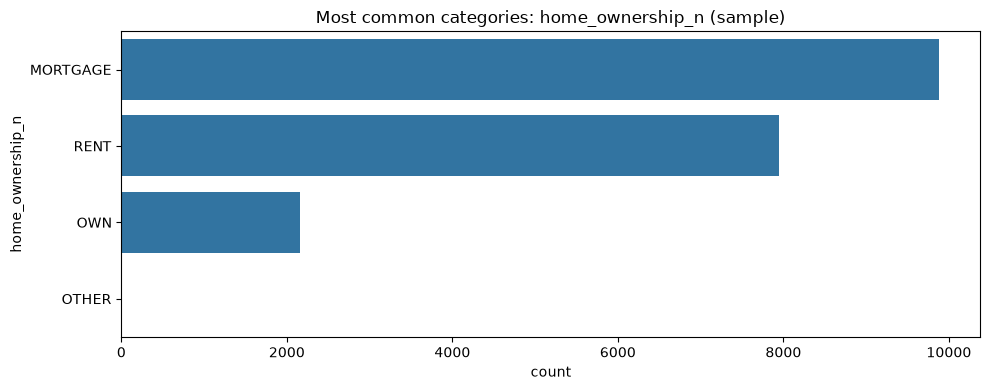

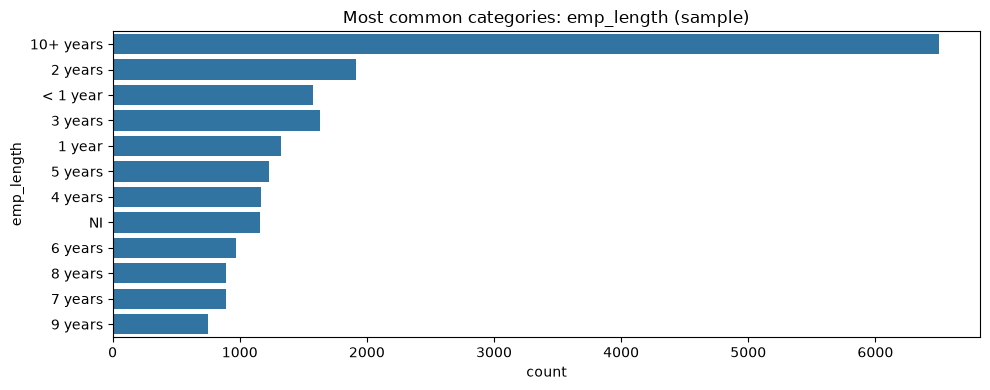

In [24]:
# Categorical distributions
for col in ["purpose", "home_ownership_n", "emp_length"]:
    if col in df.columns:
        plt.figure(figsize=(10, 4))
        order = df[col].value_counts().head(15).index
        sns.countplot(data=eda_sample, y=col, order=order)
        plt.title(f"Most common categories: {col} (sample)")
        plt.tight_layout()
        plt.show()

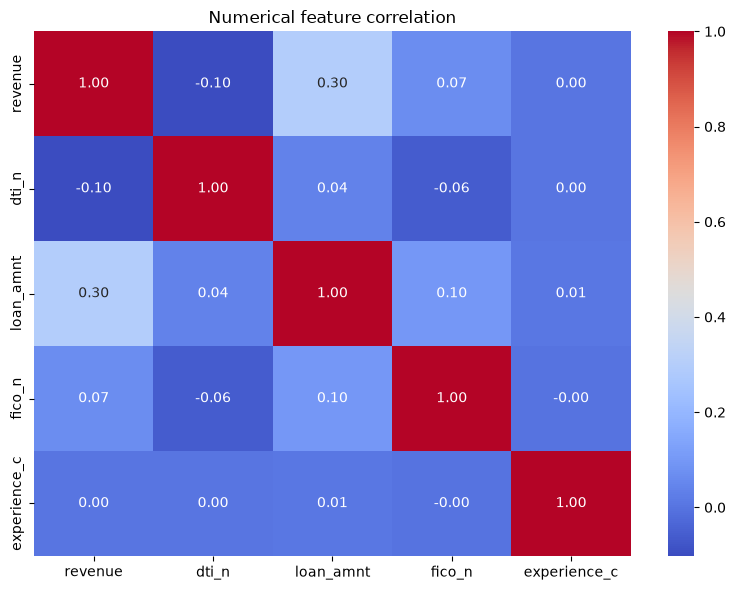

In [25]:

# Correlation among numerical fields
if len(NumData_for_eda) >= 2:
    plt.figure(figsize=(8, 6))
    sns.heatmap(df[NumData_for_eda].sample(
        n=min(100000, len(df)), random_state=RANDOM_STATE
    ).corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Numerical feature correlation")
    plt.tight_layout()
    plt.show()

## 5. FEATURE ENGINEERING AND SCALING

In [26]:
numeric_features = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n",
    "experience_c",
    "issue_year",
    "issue_month"
]

categorical_features = [
    "emp_length",
    "purpose",
    "home_ownership_n", 
]


In [27]:
print("Numeric clustering features:", numeric_features)
print("Categorical clustering features:", categorical_features)

Numeric clustering features: ['revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'issue_year', 'issue_month']
Categorical clustering features: ['emp_length', 'purpose', 'home_ownership_n']


In [28]:
feature_columns = numeric_features + categorical_features
print("Total input features before encoding:", len(feature_columns))

Total input features before encoding: 10


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])


In [30]:
try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", one_hot)
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
], remainder="drop", verbose_feature_names_out=False)

print("Feature preprocessing pipeline defined.")

Feature preprocessing pipeline defined.


In [31]:
# Separate feature data from historical outcome.
X_raw = df[feature_columns].copy()
y_default = pd.to_numeric(df["Default"], errors="coerce")

In [32]:
CLUSTER_SAMPLE_SIZE = 1000000
sample_size = min(CLUSTER_SAMPLE_SIZE, len(X_raw))

sample_idx = np.random.default_rng(RANDOM_STATE).choice(
    len(X_raw), size=sample_size, replace=False
)

X_sample_raw = X_raw.iloc[sample_idx].copy()
default_sample = y_default.iloc[sample_idx].reset_index(drop=True)
sample_metadata = df.iloc[sample_idx].reset_index(drop=True)

X_processed = preprocessor.fit_transform(X_sample_raw)
X_processed = np.asarray(X_processed, dtype=np.float32)

print("Raw sample shape:", X_sample_raw.shape)
print("Processed matrix shape:", X_processed.shape)
print("Processed matrix dtype:", X_processed.dtype)

Raw sample shape: (1000000, 10)
Processed matrix shape: (1000000, 37)
Processed matrix dtype: float32


## 6. Dimentionality Reduction

Original processed dimensions: 37
PCA dimensions retained: 12
Cumulative explained variance: 0.90836155


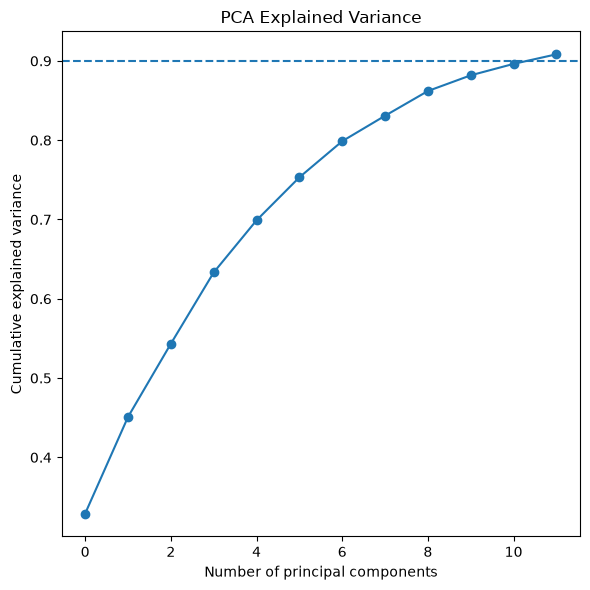

In [33]:
from sklearn.decomposition import PCA

pca_full = PCA(n_components=0.90, random_state=RANDOM_STATE)
X_pca = pca_full.fit_transform(X_processed)

print("Original processed dimensions:", X_processed.shape[1])
print("PCA dimensions retained:", X_pca.shape[1])
print("Cumulative explained variance:", pca_full.explained_variance_ratio_.sum())

plt.figure(figsize=(6, 6))
plt.plot(np.cumsum(pca_full.explained_variance_ratio_), marker="o")
plt.axhline(0.90, linestyle="--")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA Explained Variance")
plt.tight_layout()
plt.show()

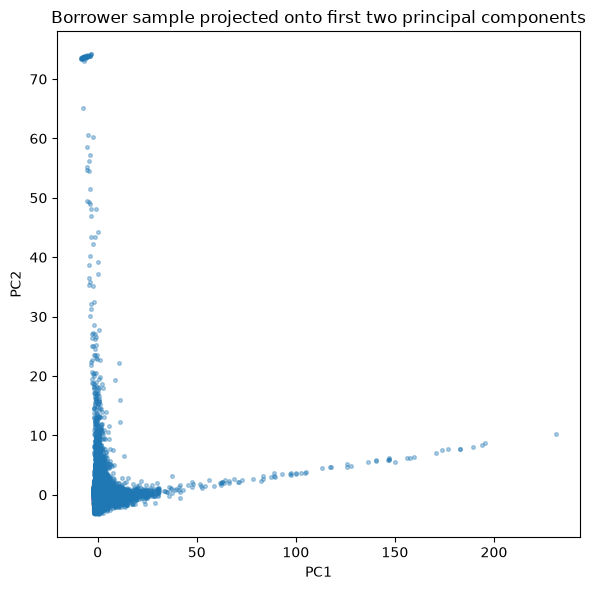

Variance explained by first two PCs: 0.45098716


In [34]:
# 2D PCA projection for visualization
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X_processed)

plt.figure(figsize=(6, 6))
plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], s=7, alpha=0.35)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Borrower sample projected onto first two principal components")
plt.tight_layout()
plt.show()

print("Variance explained by first two PCs:",
      pca_2d.explained_variance_ratio_.sum())

In [35]:
from sklearn.manifold import TSNE

TSNE_SAMPLE_SIZE = min(3000, len(X_processed))
tsne_idx = np.random.default_rng(RANDOM_STATE + 3).choice(
    len(X_processed), TSNE_SAMPLE_SIZE, replace=False
)
X_tsne_input = X_processed[tsne_idx]

pre_tsne_components = min(30, X_tsne_input.shape[1], X_tsne_input.shape[0] - 1)
X_tsne_pre = PCA(
    n_components=pre_tsne_components,
    random_state=RANDOM_STATE
).fit_transform(X_tsne_input)

perplexity_value = min(30, max(5, (TSNE_SAMPLE_SIZE - 1) // 3))
tsne = TSNE(
    n_components=2,
    random_state=RANDOM_STATE,
    init="pca",
    learning_rate="auto",
    perplexity=perplexity_value
)
X_tsne_2d = tsne.fit_transform(X_tsne_pre)

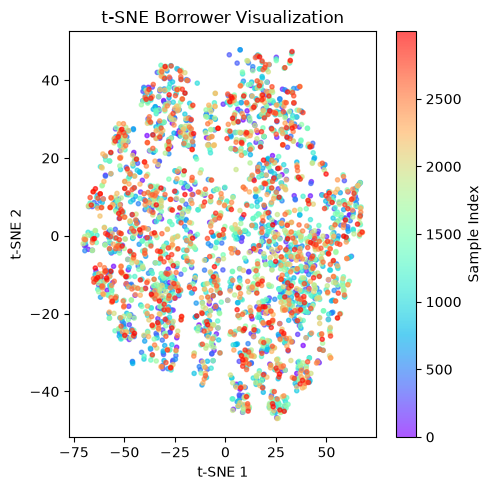

In [36]:
plt.figure(figsize=(5, 5))

plt.scatter(
    X_tsne_2d[:, 0],
    X_tsne_2d[:, 1],
    c=np.arange(len(X_tsne_2d)),
    cmap='rainbow',
    s=9,
    alpha=0.65
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("t-SNE Borrower Visualization")
plt.colorbar(label="Sample Index")
plt.tight_layout()
plt.show()

In [37]:
%pip install umap-learn

Note: you may need to restart the kernel to use updated packages.


In [38]:
import umap

umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric='euclidean',
    random_state=42,
    n_jobs=1,
    compatibility_layout=True
)

X_umap_2d = umap_model.fit_transform(X_processed)

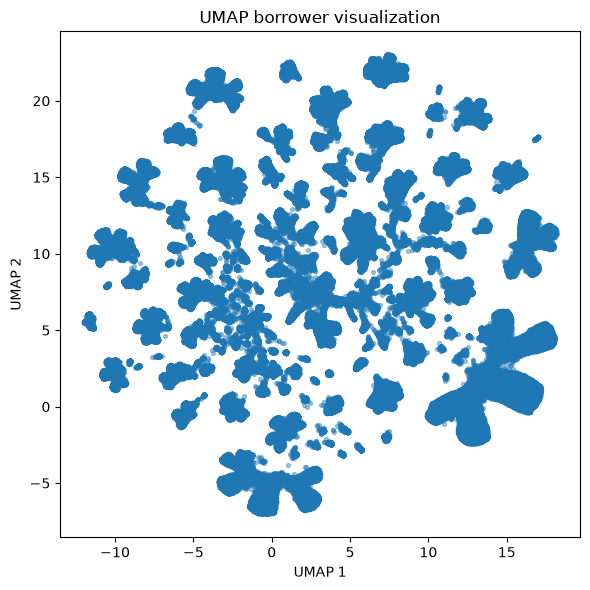

In [39]:
plt.figure(figsize=(6, 6))
plt.scatter(X_umap_2d[:, 0], X_umap_2d[:, 1], s=8, alpha=0.4)
plt.xlabel("UMAP 1")    
plt.ylabel("UMAP 2")
plt.title("UMAP borrower visualization")
plt.tight_layout()
plt.show()

## 7 Clustering Analysis

In [40]:
#K-means Clustering

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import IsolationForest

KMEANS_EVAL_SIZE = min(1000000, len(X_processed))
eval_idx = np.random.default_rng(RANDOM_STATE + 10).choice(
    len(X_processed), KMEANS_EVAL_SIZE, replace=False
)
X_eval = X_processed[eval_idx]

k_results = []
candidate_ks = [2, 3, 4, 5, 6, 7, 8]

for k in candidate_ks:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_eval)
    score = silhouette_score(X_eval, labels, sample_size=min(5000, len(X_eval)),
                             random_state=RANDOM_STATE)
    k_results.append({"k": k, "inertia": model.inertia_, "silhouette": score})

k_results_df = pd.DataFrame(k_results)
display(k_results_df)

,k,inertia,silhouette
0,2,6441703.0,0.182630
1,3,5661434.0,0.177836
2,4,5297581.0,0.090610
3,5,4967169.0,0.099138
4,6,4688145.5,0.100657
5,7,4501906.5,0.096976
6,8,4222904.0,0.093496


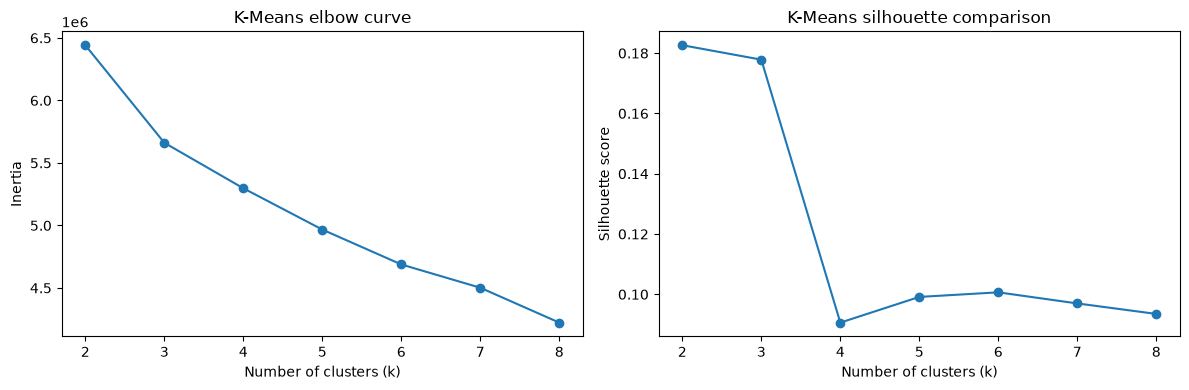

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_results_df["k"], k_results_df["inertia"], marker="o")
axes[0].set_title("K-Means elbow curve")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_results_df["k"], k_results_df["silhouette"], marker="o")
axes[1].set_title("K-Means silhouette comparison")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

In [42]:
best_k = int(k_results_df.loc[k_results_df["silhouette"].idxmax(), "k"])
print("Starting k selected by silhouette:", best_k)

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=10
)
kmeans_labels = kmeans_model.fit_predict(X_processed)

print("K-Means cluster counts:")
display(pd.Series(kmeans_labels).value_counts().sort_index().rename("borrower_count"))

Starting k selected by silhouette: 2
K-Means cluster counts:


0    756798
1    243202
Name: borrower_count, dtype: int64

In [43]:
# Hierarchical clustering
HIERARCHICAL_SIZE = min(3000, len(X_processed))
hier_idx = np.random.default_rng(RANDOM_STATE + 20).choice(
    len(X_processed), HIERARCHICAL_SIZE, replace=False
)
X_hier = X_processed[hier_idx]

hier_model = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
hier_labels = hier_model.fit_predict(X_hier)

print("Hierarchical cluster counts:")
display(pd.Series(hier_labels).value_counts().sort_index().rename("borrower_count"))

hier_silhouette = silhouette_score(
    X_hier, hier_labels, sample_size=min(3000, len(X_hier)),
    random_state=RANDOM_STATE
)
print("Hierarchical silhouette score:", round(hier_silhouette, 4))

Hierarchical cluster counts:


0    2999
1       1
Name: borrower_count, dtype: int64

Hierarchical silhouette score: 0.9485


In [44]:
#DBSCAN
DBSCAN_SIZE = min(8000, len(X_processed))
db_idx = np.random.default_rng(RANDOM_STATE + 30).choice(
    len(X_processed), DBSCAN_SIZE, replace=False
)
X_db = X_processed[db_idx]

In [45]:
min_samples_value = 10
neighbors = NearestNeighbors(n_neighbors=min_samples_value)
neighbors_fit = neighbors.fit(X_db)
distances, _ = neighbors_fit.kneighbors(X_db)
k_distances = np.sort(distances[:, -1])

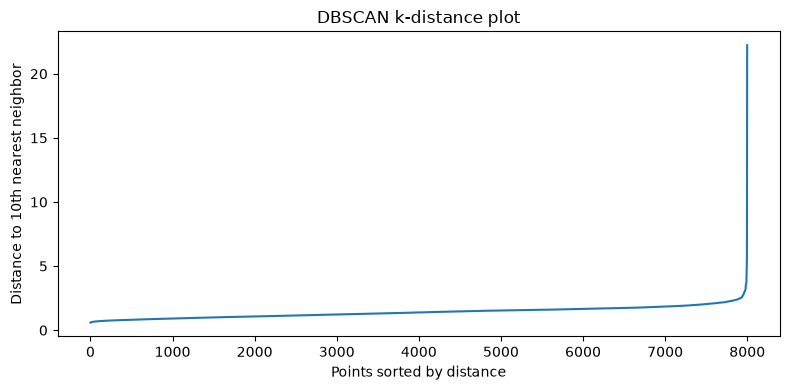

In [46]:
plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples_value}th nearest neighbor")
plt.title("DBSCAN k-distance plot")
plt.tight_layout()
plt.show()

In [47]:
DBSCAN_EPS = float(np.quantile(k_distances, 0.90))
dbscan_model = DBSCAN(eps=DBSCAN_EPS, min_samples=min_samples_value, n_jobs=-1)
dbscan_labels = dbscan_model.fit_predict(X_db)

print("DBSCAN eps:", DBSCAN_EPS)
print("DBSCAN label counts (-1 is noise):")
display(pd.Series(dbscan_labels).value_counts().sort_index().rename("borrower_count"))

non_noise = dbscan_labels != -1
n_db_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
if n_db_clusters >= 2 and non_noise.sum() > n_db_clusters:
    db_silhouette = silhouette_score(
        X_db[non_noise], dbscan_labels[non_noise],
        sample_size=min(3000, non_noise.sum()),
        random_state=RANDOM_STATE
    )
    print("DBSCAN silhouette (excluding noise):", round(db_silhouette, 4))
else:
    print("DBSCAN did not produce at least two non-noise clusters; silhouette is not defined.")

DBSCAN eps: 1.8980963230133059
DBSCAN label counts (-1 is noise):


-1     271
 0    7729
Name: borrower_count, dtype: int64

DBSCAN did not produce at least two non-noise clusters; silhouette is not defined.


## 8 Clustering Evaluation

In [48]:
#Kmeans
kmeans_eval_labels = kmeans_model.predict(X_eval)

evaluation_rows = [{
    "algorithm": "K-Means",
    "sample_size": len(X_eval),
    "n_clusters": len(np.unique(kmeans_eval_labels)),
    "silhouette": silhouette_score(
        X_eval, kmeans_eval_labels,
        sample_size=min(5000, len(X_eval)),
        random_state=RANDOM_STATE
    ),
    "davies_bouldin": davies_bouldin_score(X_eval, kmeans_eval_labels),
    "calinski_harabasz": calinski_harabasz_score(X_eval, kmeans_eval_labels)
}, {
    "algorithm": "Hierarchical",
    "sample_size": len(X_hier),
    "n_clusters": len(np.unique(hier_labels)),
    "silhouette": hier_silhouette,
    "davies_bouldin": davies_bouldin_score(X_hier, hier_labels),
    "calinski_harabasz": calinski_harabasz_score(X_hier, hier_labels)
}]

if n_db_clusters >= 2 and non_noise.sum() > n_db_clusters:
    evaluation_rows.append({
        "algorithm": "DBSCAN (noise excluded)",
        "sample_size": int(non_noise.sum()),
        "n_clusters": n_db_clusters,
        "silhouette": db_silhouette,
        "davies_bouldin": davies_bouldin_score(X_db[non_noise], dbscan_labels[non_noise]),
        "calinski_harabasz": calinski_harabasz_score(X_db[non_noise], dbscan_labels[non_noise])
    })

evaluation_df = pd.DataFrame(evaluation_rows)
display(evaluation_df)

,algorithm,sample_size,n_clusters,silhouette,davies_bouldin,calinski_harabasz
0,K-Means,1000000,2,0.182630,2.136397,128357.891249
1,Hierarchical,3000,2,0.948493,0.035941,690.965628


In [49]:
clustered_sample = sample_metadata.copy()
clustered_sample["cluster"] = kmeans_labels
clustered_sample["Default"] = default_sample.to_numpy()

print("Cluster sizes:")
display(clustered_sample["cluster"].value_counts().sort_index().to_frame("borrowers"))

Cluster sizes:


,borrowers
cluster,
0,756798
1,243202


In [52]:

profile_numeric = ["revenue", "dti_n", "loan_amnt", "fico_n", "issue_year", "issue_month"] 

cluster_numeric_profile = clustered_sample.groupby("cluster")[profile_numeric].median().round(2)
display(cluster_numeric_profile)

for col in ["purpose", "home_ownership_n", "emp_length", "addr_state"]:
    if col in clustered_sample.columns:
        print(f"Most common {col} in each cluster:")
        display(clustered_sample.groupby("cluster")[col]
                .agg(lambda x: x.value_counts().index[0]))

,revenue,dti_n,loan_amnt,fico_n,issue_year,issue_month
cluster,,,,,,
0,55373.44,18.5,10000.0,687.0,2015.0,7.0
1,120000.00,15.1,24000.0,702.0,2015.0,6.0


Most common purpose in each cluster:


cluster
0    debt_consolidation
1    debt_consolidation
Name: purpose, dtype: str

Most common home_ownership_n in each cluster:


cluster
0        RENT
1    MORTGAGE
Name: home_ownership_n, dtype: str

Most common emp_length in each cluster:


cluster
0    10+ years
1    10+ years
Name: emp_length, dtype: str

Most common addr_state in each cluster:


cluster
0    CA
1    CA
Name: addr_state, dtype: str

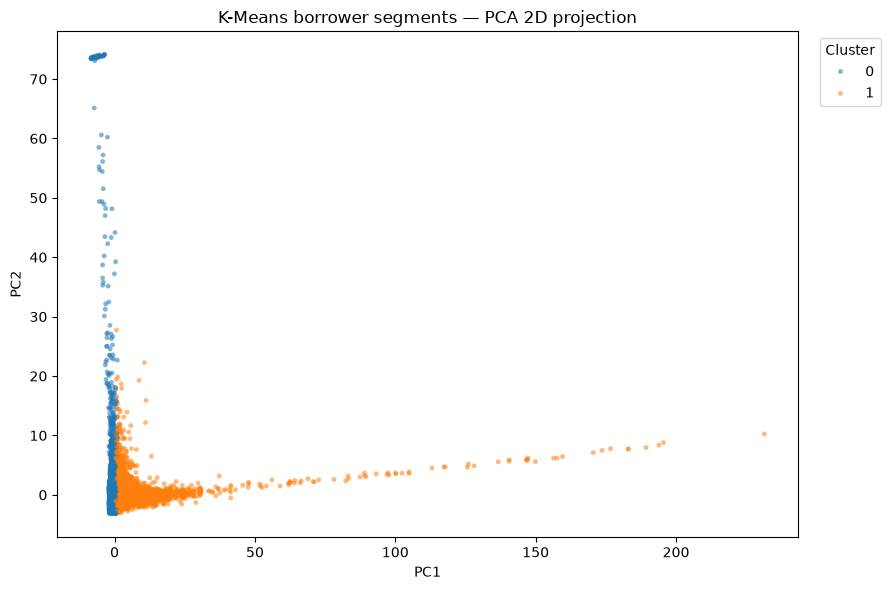

In [51]:
# Visualize clusters on the first two PCA dimensions.
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=X_pca_2d[:, 0],
    y=X_pca_2d[:, 1],
    hue=kmeans_labels.astype(str),
    palette="tab10",
    s=12,
    alpha=0.55,
    linewidth=0
)
plt.title("K-Means borrower segments — PCA 2D projection")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 9 Post Clustering Analysis

In [53]:
default_profile = clustered_sample.groupby("cluster").agg(
    borrower_count=("Default", "size"),
    historical_default_rate=("Default", "mean"),
    default_count=("Default", "sum")
).reset_index()

default_profile["historical_default_rate_pct"] = (
    default_profile["historical_default_rate"] * 100
)
display(default_profile.sort_values("historical_default_rate", ascending=False))

,cluster,borrower_count,historical_default_rate,default_count,historical_default_rate_pct
0,0,756798,0.208580,157853,20.858010
1,1,243202,0.172741,42011,17.274118


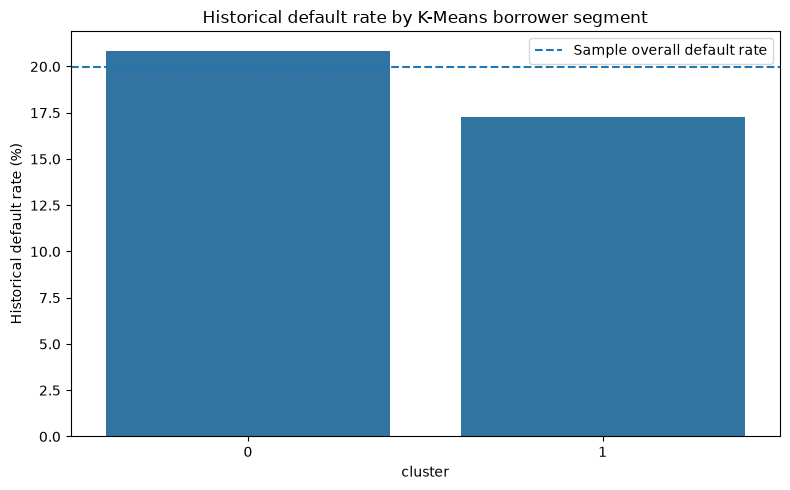

In [54]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=default_profile,
    x="cluster",
    y="historical_default_rate_pct"
)
plt.axhline(
    clustered_sample["Default"].mean() * 100,
    linestyle="--",
    label="Sample overall default rate"
)
plt.ylabel("Historical default rate (%)")
plt.title("Historical default rate by K-Means borrower segment")
plt.legend()
plt.tight_layout()
plt.show()

In [58]:
iso_model = IsolationForest(
    n_estimators=150,
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
iso_labels = iso_model.fit_predict(X_processed)  # -1 = anomaly, 1 = inlier

clustered_sample["isolation_forest_anomaly"] = (iso_labels == -1)
print("Isolation Forest flagged:", int((iso_labels == -1).sum()), "observations")
display(clustered_sample["isolation_forest_anomaly"].value_counts().to_frame("count"))

Isolation Forest flagged: 12368 observations


,count
isolation_forest_anomaly,
False,987632
True,12368


In [59]:
anomaly_examples = clustered_sample.loc[
    clustered_sample["isolation_forest_anomaly"],
    ["revenue", "dti_n", "loan_amnt", "fico_n", "emp_length",
     "purpose", "home_ownership_n", "cluster", "Default"]
].head(20)
display(anomaly_examples)

,revenue,dti_n,loan_amnt,fico_n,emp_length,purpose,home_ownership_n,cluster,Default
1,60000.0,3.36,2100,747.0,1 year,other,OWN,0,0
27,12860.0,0.00,2200,797.0,NI,medical,OWN,0,0
122,50000.0,13.06,20000,682.0,4 years,major_purchase,OWN,0,0
241,25000.0,1.03,2200,757.0,3 years,major_purchase,RENT,0,1
255,75000.0,13.20,3000,742.0,3 years,other,OWN,0,1
373,41717.0,6.10,20000,777.0,5 years,other,OWN,0,0
402,210000.0,7.83,1500,757.0,7 years,credit_card,OWN,1,0
472,153000.0,20.78,40000,747.0,< 1 year,home_improvement,OWN,1,0
487,60000.0,3.16,5000,792.0,3 years,medical,MORTGAGE,0,0
511,360000.0,5.59,35000,697.0,3 years,credit_card,MORTGAGE,1,0


In [60]:
# Consolidated cluster summary
business_summary = clustered_sample.groupby("cluster").agg(
    borrower_count=("cluster", "size"),
    median_annual_income=("revenue", "median"),
    median_dti=("dti_n", "median"),
    median_loan_amount=("loan_amnt", "median"),
    median_fico=("fico_n", "median"),
    historical_default_rate=("Default", "mean"),
    anomaly_count=("isolation_forest_anomaly", "sum")
).reset_index()

business_summary["historical_default_rate_pct"] = (
    business_summary["historical_default_rate"] * 100
)
display(business_summary.round(2))

,cluster,borrower_count,median_annual_income,median_dti,median_loan_amount,median_fico,historical_default_rate,anomaly_count,historical_default_rate_pct
0,0,756798,55373.44,18.5,10000.0,687.0,0.21,6835,20.86
1,1,243202,120000.00,15.1,24000.0,702.0,0.17,5533,17.27


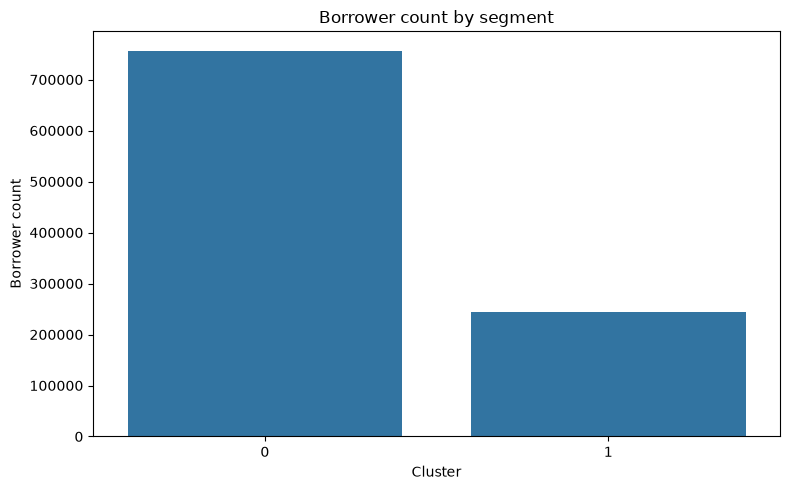

In [61]:
# Portfolio visualization: segment size
plt.figure(figsize=(8, 5))
sns.countplot(data=clustered_sample, x="cluster", order=sorted(clustered_sample["cluster"].unique()))
plt.title("Borrower count by segment")
plt.xlabel("Cluster")
plt.ylabel("Borrower count")
plt.tight_layout()
plt.show()

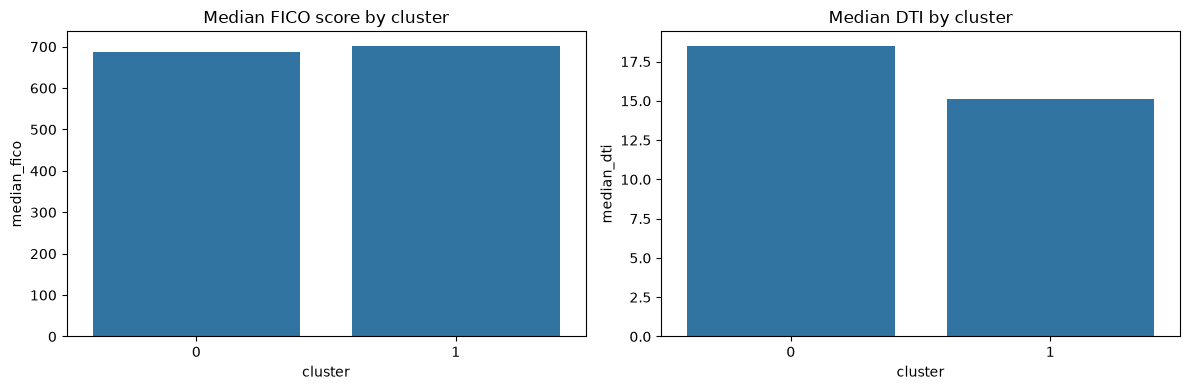

In [62]:
# Portfolio visualization: median FICO and DTI by cluster
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=business_summary, x="cluster", y="median_fico", ax=axes[0])
axes[0].set_title("Median FICO score by cluster")
sns.barplot(data=business_summary, x="cluster", y="median_dti", ax=axes[1])
axes[1].set_title("Median DTI by cluster")
plt.tight_layout()
plt.show()